# 1) Install SUMO and networkx

In [1]:
# Install the simulation tools into this Colab session (they are lost when the session ends).
# eclipse-sumo==1.28.0 : SUMO, including netconvert. Pinned to 1.28.0 because that version built bugis_all.net.xml (see the header of the net file), so rebuilding the variants reproduces C's network exactly.
# networkx : graph algorithms used by build_planning.py (betweenness, connectivity).
# contextily : map tiles; not used now that the satellite views are screenshots so it can be removed from this line.
# numpy, scipy, pandas and matplotlib are already installed in Colab.
!pip install -q eclipse-sumo==1.28.0 networkx contextily

# 2) Point Python at SUMO’s tools

In [2]:
import os, sys
import sumo

# SUMO_HOME tells SUMO's Python tools (and build_planning.py) where SUMO is installed.
# Note: importing sumo also points PROJ_LIB / PROJ_DATA at SUMO's own map-projection data,
# which can clash with pyproj if you later convert coordinates to latitude/longitude.
os.environ["SUMO_HOME"] = sumo.SUMO_HOME

# sumolib (reads SUMO network files) lives in SUMO's "tools" folder, not in pip's usual place,
# so add that folder to Python's search path before importing it.
sys.path.append(os.path.join(os.environ["SUMO_HOME"], "tools"))
import sumolib

# Check that netconvert works and is version 1.28.0.
!netconvert --version | head -1

Eclipse SUMO netconvert 1.28.0


# 3) upload 8 files,

### build_planning.py
### bugis_all_base.net.xml
### bugis_all_closure.net.xml
### bugis_all_lanecut.net.xml
### bugis_all_newlink.net.xml
### bugis_all_closure.meta.json
### bugis_all_lanecut.meta.json
### bugis_all_newink.meta.json

In [3]:
# Step 3: upload the input files.

from google.colab import files

uploaded = files.upload()

# 4) Map the baseline network

Using /content/bugis_all_base.net.xml
1129 roads, 76 signal programs, 179.7 km of car lanes
[('residential', 574), ('primary', 204), ('tertiary', 133), ('secondary', 132), ('trunk', 43), ('primary_link', 17), ('tertiary_link', 8), ('trunk_link', 7), ('living_street', 6), ('secondary_link', 4), ('unclassified', 1)]


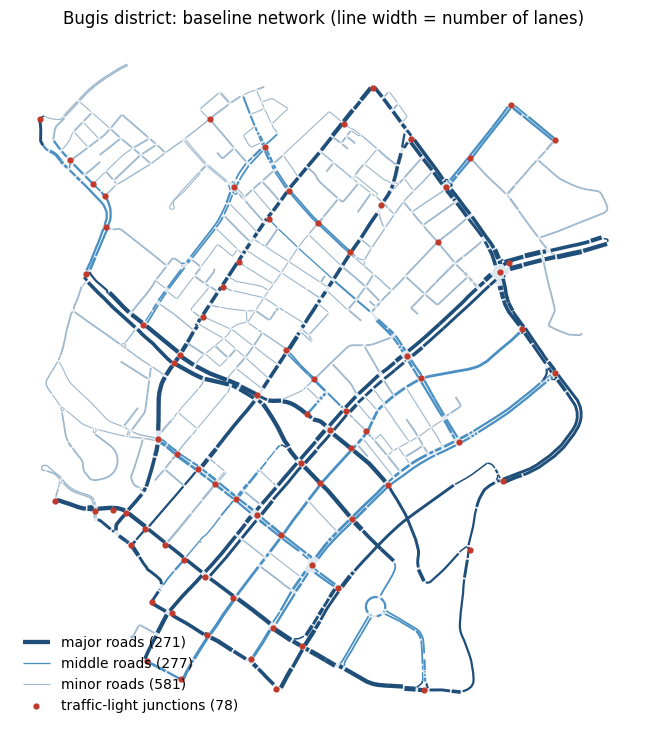

In [4]:
# --- Setup: find the network file and load sumolib --------------------------------------------
import os, subprocess, sys
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection

# The network can be uploaded under either name, or sit in the repository (also inside ./repo).
CANDIDATES = ["bugis_all.net.xml", "bugis_all_base.net.xml",
              "scenarios/city/bugis_all.net.xml", "repo/scenarios/city/bugis_all.net.xml",
              "repo/scenarios/city/bugis_all_base.net.xml"]

BASE_NET = next((p for p in CANDIDATES if os.path.exists(p)), None)
if BASE_NET is None:
    raise FileNotFoundError("No Bugis network file found: upload bugis_all.net.xml or bugis_all_base.net.xml")
print("Using", os.path.abspath(BASE_NET))

# sumolib reads SUMO network files; it is not preinstalled in Colab, so install it if needed.
try:
    import sumolib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sumolib"], check=True)
    import sumolib

# --- Load the baseline network ---------------------------------------------------------------
# withInternal=True also loads the short lanes inside junctions; they are skipped when drawing
# roads, but the junction outlines are drawn below to fill the gaps between road pieces.
net = sumolib.net.readNet(BASE_NET, withInternal=True)
# "Edges" are SUMO's road pieces: one direction of a road between two junctions.
# Internal edges (inside junctions) are left out here.
edges = [e for e in net.getEdges() if e.getFunction() != "internal"]

# Total length of lanes that cars may use (edge length x number of car lanes).
# This is the denominator of density: density = number of cars / car-lane length.
car_lane_m = sum(e.getLength() * sum(l.allows("passenger") for l in e.getLanes()) for e in edges)
print(f"{len(edges)} roads, {len(net.getTrafficLights())} signal programs, "
      f"{car_lane_m / 1000:.1f} km of car lanes")
# Count road pieces by OpenStreetMap road class (residential, primary, ...).
print(Counter(e.getType().replace("highway.", "") for e in edges).most_common())

# --- Map style -------------------------------------------------------------------------------
# Road classes are grouped into three groups for colouring; anything not listed is "minor".
GROUPS = {"trunk": "major", "primary": "major", "secondary": "middle", "tertiary": "middle"}
# group -> (line colour, width scale). Line width also grows with the number of lanes.
STYLE = {"major": ("#1f4e79", 1.0), "middle": ("#4a90c2", 0.7), "minor": ("#9db7cc", 0.4)}


def road_group(e):
    """Map group of one road piece; slip roads ("primary_link") count as their main class."""
    return GROUPS.get(e.getType().replace("highway.", "").removesuffix("_link"), "minor")


# --- Draw ------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 9))
# Junction areas as light grey shapes, so roads look continuous through junctions.
ax.add_collection(PolyCollection([n.getShape() for n in net.getNodes() if len(n.getShape()) > 2],
                                 facecolors="#dfe7ee", edgecolors="none"))
# Roads, one group at a time (one legend entry per group).
for group, (colour, scale) in STYLE.items():
    sel = [e for e in edges if road_group(e) == group]
    ax.add_collection(LineCollection([e.getShape() for e in sel], colors=colour,
                                     linewidths=[0.6 + scale * e.getLaneNumber() * 0.5 for e in sel],
                                     label=f"{group} roads ({len(sel)})"))
# Junctions with traffic lights as red dots. There are 78 such junctions but 76 signal
# programs, because a few programs control two neighbouring junctions together.
tls = [n.getCoord() for n in net.getNodes() if n.getType().startswith("traffic_light")]
ax.scatter(*zip(*tls), s=12, color="#c0392b", zorder=3, label=f"traffic-light junctions ({len(tls)})")
# Fit the view to the network, keep metres equal in x and y, and hide the axes.
ax.autoscale()
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Bugis district: baseline network (line width = number of lanes)")
ax.legend(loc="lower left", frameon=False)
plt.show()

# 5) Build the variants

In [5]:
# Step 6: build the three planning variants from bugis_all.net.xml (takes about 20 s).
# For each variant the script writes, next to the base net:
#   bugis_all_<variant>.patch.xml : the small change applied to C's network
#   bugis_all_<variant>.net.xml   : the resulting network (built by netconvert)
#   bugis_all_<variant>.meta.json : what changed, lane lengths, the ranking and the build checks
# --assume-existing: Java Road (between these two junctions) exists in reality but is missing
# from C's network. The new-link ranking treats it as existing, so the script does not pick
# that gap as a "new" road. Remove the option once C adds Java Road to the network.
!python scenarios/city/build_planning.py --net scenarios/city/bugis_all.net.xml \
    --assume-existing "2015359629:cluster_240661028_240661099"

python3: can't open file '/content/scenarios/city/build_planning.py': [Errno 2] No such file or directory


In [6]:
!python scenarios/city/build_planning.py --net scenarios/city/bugis_all.net.xml --allow-internal-rebuild

python3: can't open file '/content/scenarios/city/build_planning.py': [Errno 2] No such file or directory


In [7]:
!ls scenarios/city

ls: cannot access 'scenarios/city': No such file or directory


In [8]:
!grep -o '"length_m": [0-9.]*\|"from": "[^"]*"' scenarios/city/bugis_all_newlink.meta.json

grep: scenarios/city/bugis_all_newlink.meta.json: No such file or directory


# 6) Summary tables

In [9]:
import json, os
import pandas as pd
pd.set_option("display.max_colwidth", None)   # show long text in full instead of cutting it off

# --- Find the three summary files (written by build_planning.py, or uploaded) -------------------
# Full paths, so the current working folder doesn't matter.
FOLDERS = ["/content", "/content/scenarios/city", "/content/repo/scenarios/city"]
VARIANTS = ["closure", "lanecut", "newlink"]

def find_meta(v):
    """Full path of bugis_all_<v>.meta.json in the first folder that has it."""
    name = f"bugis_all_{v}.meta.json"
    for folder in FOLDERS:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"{name} not found in {FOLDERS}")

meta = {}
for v in VARIANTS:
    path = find_meta(v)
    print("Using", path)
    meta[v] = json.load(open(path))
base_len = meta["closure"]["baseline_lane_length_m"]   # car-lane length of the unchanged network

# --- Table 1: one row per variant --------------------------------------------------------------
rows = []
for v, m in meta.items():
    c, bc = m["change"], m["build_check"]   # c: what was changed; bc: checks on the built network
    # Describe the change in words; the fields differ by type of change.
    if c["type"] == "remove":
        what = f"{c['street']}: both directions removed ({'+'.join(map(str, c['lanes']))} lanes)"
    elif c["type"] == "lanecut":
        what = (f"{c['street']}: lanes {'+'.join(map(str, c['lanes_before']))} -> "
                f"{'+'.join(map(str, c['lanes_after']))}")
    else:
        what = f"new two-way road, {c['length_m']:.0f} m, {c['lanes']} lane each way"
    rows.append({"variant": v, "change": what,
                 # Car-lane length of the variant, and its difference from the baseline in %.
                 "car lane length (km)": round(m["lane_length_m"] / 1000, 3),
                 "vs baseline (%)": round(100 * (m["lane_length_m"] / base_len - 1), 2),
                 # Traffic-light programs that netconvert had to change (junctions that lost or
                 # gained turns).
                 "signal programs changed": len(bc["signal_programs_changed"]),
                 # Lane-to-lane turns between roads that disappeared or were added.
                 "turns removed": len(bc["connections_removed"]),
                 "turns added": len(bc["connections_added"]),
                 # Every car road can still be reached from every other (C's controller needs it).
                 "all roads reachable": bc["all_car_edges_reachable"]})
display(pd.DataFrame(rows).set_index("variant"))

# --- Table 2: why Victoria Street was chosen for the closure -------------------------------------
# Road segments ranked by betweenness: how many shortest routes (by free-flow travel time)
# between all pairs of junctions pass along them. The closure takes the highest-ranked
# segment whose removal still leaves every road reachable.
def street_name(edge_id):
    """Street name from the network loaded in the map cell (`net`), if that cell has run."""
    try:
        return net.getEdge(edge_id).getName()
    except NameError:                      # the map cell has not run: no network loaded
        return "(run the map cell first)"

rank = meta["closure"]["ranking"]
print("Closure candidates, highest betweenness first:")
display(pd.DataFrame([{"segment": r["segment"], "street": street_name(r["edges"][0]),
                       "betweenness": r["betweenness"],
                       "keeps network connected": r["keeps_connected"]} for r in rank[:6]]))

Using /content/bugis_all_closure.meta.json
Using /content/bugis_all_lanecut.meta.json
Using /content/bugis_all_newlink.meta.json


,change,car lane length (km),vs baseline (%),signal programs changed,turns removed,turns added,all roads reachable
variant,,,,,,,
closure,Victoria Street: both directions removed (4+3 lanes),179.115,-0.32,2,18,0,True
lanecut,Victoria Street: lanes 4+3 -> 3+2,179.518,-0.10,2,4,0,True
newlink,"new two-way road, 148 m, 1 lane each way",179.946,0.14,0,0,6,True


Closure candidates, highest betweenness first:


,segment,street,betweenness,keeps network connected
0,539844638,Jalan Besar,65646.0,False
1,538223044#0~630437927#0,Victoria Street,59741.0,True
2,481102416,Jalan Besar,56815.0,False
3,829560362,Jalan Besar,56147.0,False
4,829565054,Jalan Besar,50234.0,False
5,396336423#0~585630264#0,Sungei Road,49209.0,False


### Victoria Street is the busiest road segment on shortest routes whose closure still leaves every road reachable.

**change**: what the patch does. Closure removes both directions of the Victoria Street stretch (4 lanes one way, 3 the other). The lane cut keeps the road but takes one lane from each direction. The new link adds a 148 m road with one lane each way.


**car lane length and vs baseline**: the network’s total lane length, the denominator of density. No change moves it by more than 0.32%. If you plotted against each variant’s own density, the shift would be tiny, but holding the car count fixed (as agreed) avoids even that.

**signal programs changed**: the closure and lane cut each alter the two traffic lights at the ends of Victoria Street, since those junctions lose turns. That comes with any closure. The new link alters none, by design.

**turns removed / added**: individual lane-to-lane turns at junctions. The closure loses 17 (every turn into and out of the removed road). The lane cut loses 5 (turns that used the removed lanes). The new link adds 6 (into and out of the new road).

**all roads reachable**: every road can still be reached from every other in all three variants. That’s what C’s controller needs, and why the closure rule skipped Jalan Besar.

# 7) Map of the variants

Using /content/bugis_all_base.net.xml
Using /content/bugis_all_closure.net.xml
Using /content/bugis_all_lanecut.net.xml
Using /content/bugis_all_newlink.net.xml


closed: ['538223044#0', '630437927#0'] | lane cut: ['538223044#0', '630437927#0'] | new: ['newlink_2015359629_cluster_240661028_240661099', 'newlink_cluster_240661028_240661099_2015359629']


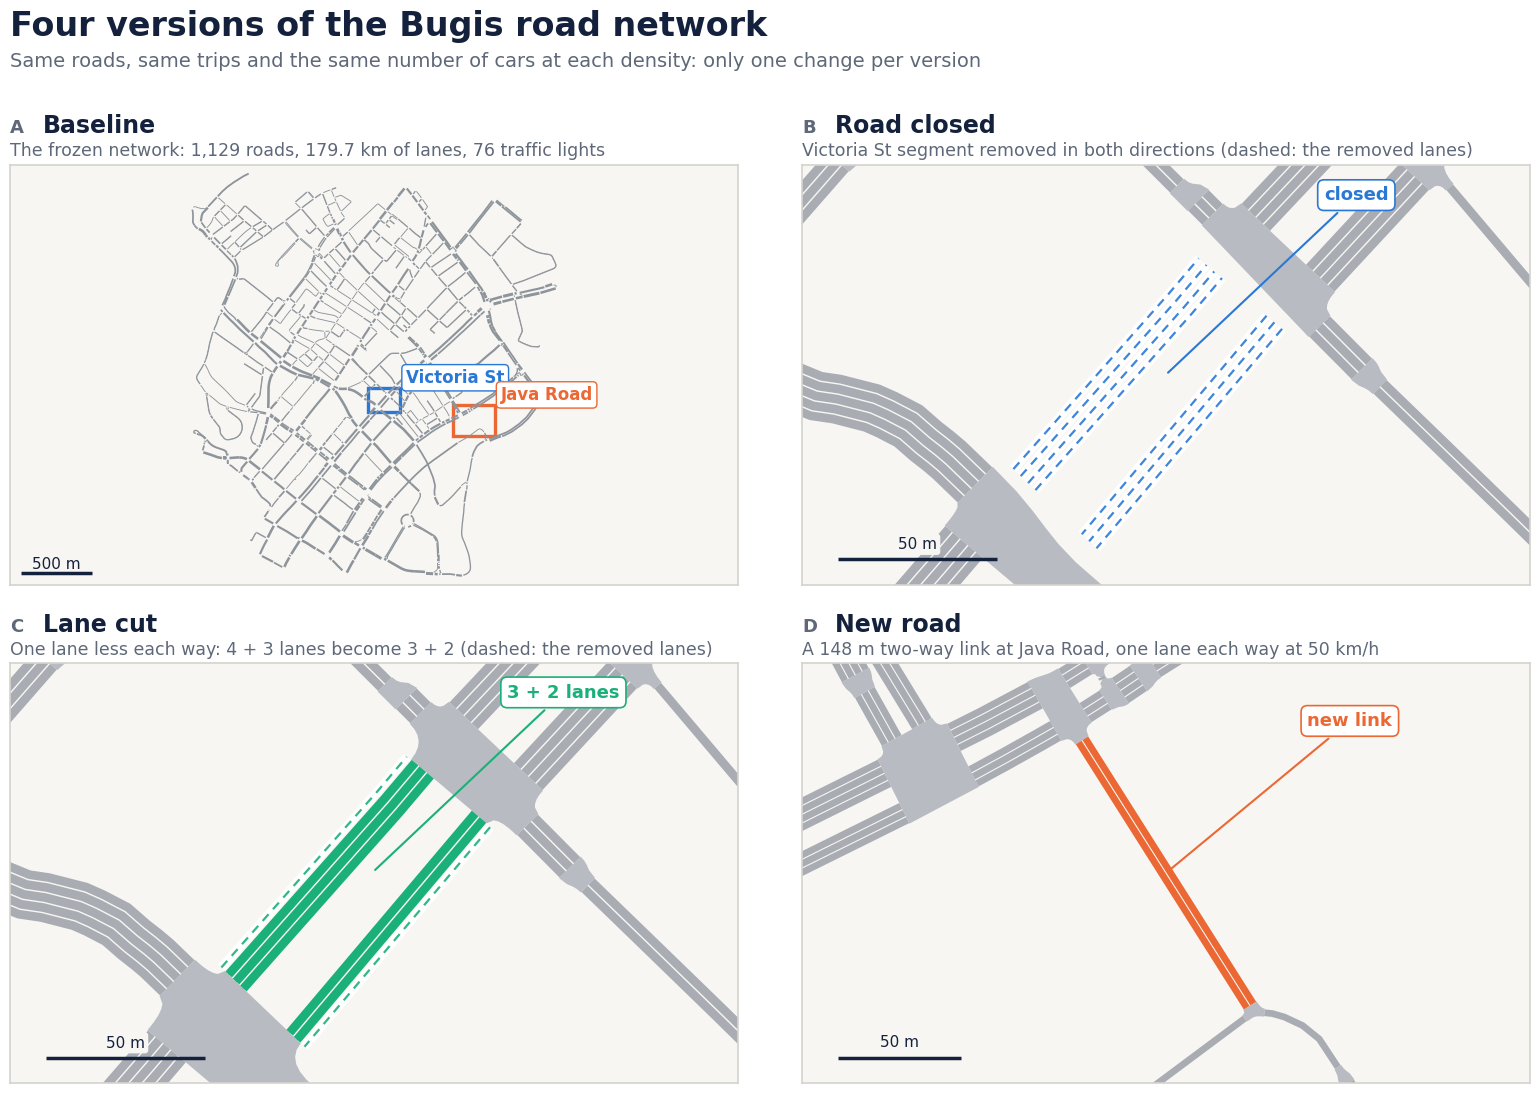

In [10]:
# --- Four versions of the Bugis network: baseline, road closed, lane cut, new road -------------
# Draws every lane at its true width from the four network files, so each change is visible.
# Needs 4 files (made by build_planning.py, or uploaded):
#   bugis_all_base.net.xml (or bugis_all.net.xml), bugis_all_closure.net.xml,
#   bugis_all_lanecut.net.xml, bugis_all_newlink.net.xml
# No SUMO or sumolib needed: the shapes are read straight from the XML.
import os
import xml.etree.ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.patches import Rectangle

# --- Find the four network files (full paths, so the current folder doesn't matter) ----------
FOLDERS = ["/content", "/content/scenarios/city", "/content/repo/scenarios/city", ".", "scenarios/city"]
NAMES = {"base": ["bugis_all_base.net.xml", "bugis_all.net.xml"],
         "closure": ["bugis_all_closure.net.xml"], "lanecut": ["bugis_all_lanecut.net.xml"],
         "newlink": ["bugis_all_newlink.net.xml"]}

def find_net(variant):
    """Full path of the variant's network file in the first folder that has it."""
    for folder in FOLDERS:
        for name in NAMES[variant]:
            path = os.path.join(folder, name)
            if os.path.exists(path):
                return path
    raise FileNotFoundError(f"{' or '.join(NAMES[variant])} not found in {FOLDERS}")

# --- Read a network: every lane's centre line, the junction areas, and a few totals ----------
def read(path):
    """({road id: [lane centre lines]}, [junction outlines], car-lane length in m, signal programs)."""
    edges, juncs, car_m, n_tls = {}, [], 0.0, 0
    for _, el in ET.iterparse(path):
        if el.tag == "edge" and el.get("function") != "internal":
            lanes = []
            for ln in el.findall("lane"):
                lanes.append(np.array([[float(c) for c in p.split(",")[:2]] for p in ln.get("shape").split()]))
                allow, disallow = ln.get("allow"), (ln.get("disallow") or "").split()
                if (allow is None or "passenger" in allow.split()) and "passenger" not in disallow:
                    car_m += float(ln.get("length"))               # lanes cars may use
            if lanes:
                edges[el.get("id")] = lanes
            el.clear()
        elif el.tag == "junction" and el.get("type") != "internal" and el.get("shape"):
            pts = np.array([[float(c) for c in p.split(",")[:2]] for p in el.get("shape").split()])
            if len(pts) >= 3:
                juncs.append(pts)
            el.clear()
        elif el.tag == "tlLogic":
            n_tls += 1
            el.clear()
        elif el.tag == "connection":
            el.clear()                                             # keeps memory low
    return edges, juncs, car_m, n_tls

net = {}
for v in NAMES:
    path = find_net(v)
    print("Using", path)
    net[v] = read(path)
base_e, base_j, base_car_m, base_tls = net["base"]

# What changed, found by comparing each variant with the baseline
closed = [e for e in base_e if e not in net["closure"][0]]                          # roads removed
cut = [e for e in base_e if e in net["lanecut"][0] and len(net["lanecut"][0][e]) < len(base_e[e])]  # fewer lanes
new = [e for e in net["newlink"][0] if e not in base_e]                             # roads added
print("closed:", closed, "| lane cut:", cut, "| new:", new)

# --- Style --------------------------------------------------------------------------------------
INK, MUTED, BG, ROAD, JUNC = "#14213D", "#5E6878", "#F7F6F2", "#A9ADB3", "#B8BCC2"
COL = {"closure": "#2a78d6", "lanecut": "#1baf7a", "newlink": "#eb6834"}   # blue, green, orange
LANE_W = 3.2                                                               # lane width in metres

def box(ids, edges, half):
    """(x0, x1, y0, y1) of a zoom window centred on some roads, `half` metres tall each way."""
    xy = np.vstack([l for e in ids for l in edges[e]])
    cx, cy = xy[:, 0].mean(), xy[:, 1].mean()
    return cx - half * 1.35, cx + half * 1.35, cy - half, cy + half

def pts_per_m(ax):
    """Points per metre on this panel, so lanes can be drawn at their true width."""
    ax.apply_aspect()
    x0, x1 = ax.get_xlim()
    return ax.get_position().width * ax.figure.get_figwidth() * 72 / (x1 - x0)

def draw_detail(ax, edges, juncs, xlim, ylim, highlight=(), hcolor=None, ghost=(), ghost_edges=None):
    """A zoomed panel: junctions, every lane in grey, highlighted lanes in colour, removed lanes dashed."""
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect("equal", adjustable="datalim")
    ax.set_facecolor(BG)
    k = pts_per_m(ax)
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    ax.add_collection(PolyCollection(juncs, facecolors=JUNC, edgecolors="none"))
    plain = [l for e, ls in edges.items() if e not in highlight for l in ls]
    ax.add_collection(LineCollection(plain, colors=ROAD, linewidths=(LANE_W - 0.45) * k, capstyle="butt"))
    if ghost:      # lanes that existed in the baseline but not here: white with a dashed outline
        g = [l for e in ghost for l in ghost_edges[e]]
        ax.add_collection(LineCollection(g, colors="#FFFFFF", linewidths=(LANE_W - 0.45) * k, capstyle="butt"))
        ax.add_collection(LineCollection(g, colors=hcolor, linewidths=1.6, linestyles=(0, (4, 3)), alpha=0.9))
    if highlight:  # lanes that are still there but changed (lane cut) or new (new link)
        h = [l for e in highlight for l in edges[e]]
        ax.add_collection(LineCollection(h, colors=hcolor, linewidths=(LANE_W - 0.45) * k, capstyle="butt"))
    x0, y0 = xlim[0] + 0.05 * (xlim[1] - xlim[0]), ylim[0] + 0.06 * (ylim[1] - ylim[0])   # 50 m scale bar
    ax.plot([x0, x0 + 50], [y0, y0], color=INK, lw=2.5, solid_capstyle="butt")
    ax.text(x0 + 25, y0 + 0.025 * (ylim[1] - ylim[0]), "50 m", ha="center", fontsize=11, color=INK,
            bbox=dict(boxstyle="round,pad=0.2", fc=BG, ec="none"))

def style(ax, letter, title, sub):
    """Panel letter, title and one-line description above the panel."""
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("#D5D3CC"); s.set_linewidth(1.2)
    ax.text(0.0, 1.075, letter, transform=ax.transAxes, fontsize=13, fontweight="bold", color=MUTED)
    ax.text(0.045, 1.075, title, transform=ax.transAxes, fontsize=17, fontweight="bold", color=INK)
    ax.text(0.0, 1.02, sub, transform=ax.transAxes, fontsize=12.5, color=MUTED)

def label(ax, ids, edges, text, c, dx, dy):
    """A boxed label with a leader line pointing at the middle of some roads."""
    xy = np.vstack([l for e in ids for l in edges[e]])
    cx, cy = xy[:, 0].mean(), xy[:, 1].mean()
    ax.annotate(text, (cx, cy), xytext=(cx + dx, cy + dy), fontsize=13, fontweight="bold", color=c,
                ha="center", arrowprops=dict(arrowstyle="-", color=c, lw=1.5),
                bbox=dict(boxstyle="round,pad=0.35", fc="#FFFFFF", ec=c, lw=1.2))

# --- Figure: 2 x 2 panels -------------------------------------------------------------------------
plt.rcParams["font.family"] = "DejaVu Sans"
fig = plt.figure(figsize=(16, 11.2), facecolor="#FFFFFF")
axes = [fig.add_axes(r) for r in ([0.03, 0.475, 0.455, 0.375], [0.525, 0.475, 0.455, 0.375],
                                  [0.03, 0.03, 0.455, 0.375], [0.525, 0.03, 0.455, 0.375])]
fig.text(0.03, 0.965, "Four versions of the Bugis road network", fontsize=24, fontweight="bold", color=INK)
fig.text(0.03, 0.937, "Same roads, same trips and the same number of cars at each density: only one change per version",
         fontsize=14, color=MUTED)

vic = box(closed, base_e, 85)                  # zoom window around Victoria St
java = box(new, net["newlink"][0], 110)        # zoom window around the new link

# (A) Baseline: the whole network, with the two sites marked
ax = axes[0]
ax.set_facecolor(BG); ax.set_aspect("equal", adjustable="datalim")
allxy = np.vstack([l for ls in base_e.values() for l in ls])
pad = 60
ax.set_xlim(allxy[:, 0].min() - pad, allxy[:, 0].max() + pad)
ax.set_ylim(allxy[:, 1].min() - pad, allxy[:, 1].max() + pad)
ax.add_collection(LineCollection([ls[len(ls) // 2] for ls in base_e.values()], colors="#8E949B",
                                 linewidths=[0.35 + 0.3 * len(ls) for ls in base_e.values()]))
for (x0, x1, y0, y1), lab, c in ((vic, "Victoria St", COL["closure"]), (java, "Java Road", COL["newlink"])):
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=c, lw=2.4))
    ax.text(x1 + 40, y1 + 10, lab, fontsize=12, color=c, fontweight="bold", va="bottom",
            bbox=dict(boxstyle="round,pad=0.25", fc="#FFFFFF", ec=c, lw=1))
ax.apply_aspect()
xl, yl = ax.get_xlim(), ax.get_ylim()
ax.plot([xl[0] + 80, xl[0] + 580], [yl[0] + 80, yl[0] + 80], color=INK, lw=2.5, solid_capstyle="butt")
ax.text(xl[0] + 330, yl[0] + 110, "500 m", ha="center", fontsize=11, color=INK)
style(ax, "A", "Baseline", f"The frozen network: {len(base_e):,} roads, {base_car_m / 1000:.1f} km of lanes, "
                           f"{base_tls} traffic lights")

# (B) Road closed: the removed lanes dashed, drawn from the baseline
draw_detail(axes[1], net["closure"][0], net["closure"][1], vic[:2], vic[2:], hcolor=COL["closure"],
            ghost=closed, ghost_edges=base_e)
style(axes[1], "B", "Road closed", "Victoria St segment removed in both directions (dashed: the removed lanes)")

# (C) Lane cut: the remaining lanes in green, the removed lane of each direction dashed
before = " + ".join(str(len(base_e[e])) for e in cut)
after = " + ".join(str(len(net["lanecut"][0][e])) for e in cut)
draw_detail(axes[2], net["lanecut"][0], net["lanecut"][1], vic[:2], vic[2:], highlight=cut, hcolor=COL["lanecut"],
            ghost=cut, ghost_edges=base_e)
style(axes[2], "C", "Lane cut", f"One lane less each way: {before} lanes become {after} (dashed: the removed lanes)")

# (D) New road: the new link in orange
link_m = 148   # m, junction to junction, as in bugis_all_newlink.meta.json (the drawn lane stops at the junction edges)
draw_detail(axes[3], net["newlink"][0], net["newlink"][1], java[:2], java[2:], highlight=new, hcolor=COL["newlink"])
style(axes[3], "D", "New road", f"A {link_m:.0f} m two-way link at Java Road, one lane each way at 50 km/h")

label(axes[1], closed, base_e, "closed", COL["closure"], 60, 55)
label(axes[2], cut, net["lanecut"][0], f"{after} lanes", COL["lanecut"], 60, 55)
label(axes[3], new, net["newlink"][0], "new link", COL["newlink"], 75, 60)

fig.savefig("bugis_four_versions.png", dpi=200, facecolor="#FFFFFF")
plt.show()

# 8.1) Satellite view (Suggested lane closure)

In [11]:
# Show a screenshot of Victoria Street (satellite view with Google's live-traffic layer).
# The file is uploaded into this session only, so it has to be uploaded again after a restart.
# (To keep an image permanently in the notebook, insert it into a text cell instead.)
# from google.colab import files
# from IPython.display import Image, display

# uploaded = files.upload()          # choose your screenshot
# for name in uploaded:
#     display(Image(filename=name, width=700))   # width in pixels
# # Caption with the required credit for Google map imagery.
# print("“Victoria Street, Ophir Rd to Arab St, live traffic. Map data © Google”.")

# 8.2) Satellite view (Suggested new link)

In [12]:
# Show a screenshot of the new-link location (same steps as 9.1).
# Use it to check what lies between the two ends: an existing road, buildings or open ground.
# from google.colab import files
# from IPython.display import Image, display

# uploaded = files.upload()          # choose your screenshot
# for name in uploaded:
#     display(Image(filename=name, width=700))